# 📘 Notebook 08: Fashion-MNIST, What Does a Computer See in a Picture?

### Course: *From Questions to Answers: Classic Datasets, Fully Explored*
**Instructor:** Ioannis Tsioulis

*Dataset 8 · Zalando's Fashion-MNIST, test file (10,000 images of 28 × 28 pixels, 10 classes)*

---

> 💡 **This notebook is already run.** Every picture, table and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything. To experiment, choose **Runtime → Run all** in Colab; the whole notebook runs in about a minute. If you rerun it, numbers from the models may differ slightly, because Colab may have newer library versions.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Read an image dataset stored in a **binary file format** and see that an image is just a **table of numbers**
- **Look** at the data: sample images, class balance, average images per class
- Find which **pixels** carry information and which are almost always empty
- Use **PCA** to compress 784 pixels into a few numbers and draw the dataset in two dimensions
- Build simple **baseline classifiers** on raw pixels and read their **confusion matrix**
- Explain which classes are hard and **why**, before any deep learning

> **Prerequisites:** [Notebook 02: Penguins](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-questions-to-answers/02_penguins.ipynb) for distances and clusters. NumPy arrays are used throughout.
>
> 🔭 **Why this notebook matters:** it is tempting to throw images straight into a neural network. But images are data like any other, and the same questions apply: are the classes balanced, what does a typical example look like, which inputs matter, which classes are confused and why? Fashion-MNIST was created by Han Xiao, Kashif Rasul and Roland Vollgraf at Zalando as a harder replacement for the famous MNIST handwritten digits; it has exactly the same format, so everything here transfers to MNIST.

## 0. The question

Each image is a small greyscale photo of one clothing item from Zalando's catalogue, in one of ten classes: T-shirt/top, trouser, pullover, dress, coat, sandal, shirt, sneaker, bag and ankle boot.

**Our question:** *How different do the ten classes look to a computer, and which ones can it tell apart without any deep learning?* More precisely:

1. What does the data look like, and how is it balanced?
2. Which parts of the picture carry the information?
3. How far do simple methods on raw pixels get, and where do they fail?

In [1]:
import warnings
warnings.filterwarnings("ignore")

import gzip
import urllib.request

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.precision", 3)
sns.set_theme(style="white")
plt.rcParams["figure.dpi"] = 80
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

## 1. Loading images from a binary file

The images are not in a CSV file. They are stored in the compact **IDX** format: a short header followed by every pixel, one byte each (0 = white background, 255 = darkest). We download the compressed files, unzip them in memory with `gzip`, and skip the header (16 bytes for images, 8 for labels). We use the official **test file** of 10,000 images, which is large enough for exploration and quick to download; the training file has 60,000 more in exactly the same format.

In [2]:
BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"

def read_idx(name, header_bytes):
    raw = gzip.decompress(urllib.request.urlopen(BASE + name).read())
    return np.frombuffer(raw, dtype=np.uint8, offset=header_bytes)

images = read_idx("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 28, 28)
labels = read_idx("t10k-labels-idx1-ubyte.gz", 8)
print("images:", images.shape, " labels:", labels.shape)
print("one image is a 28 x 28 table of numbers from", images.min(), "to", images.max())

images: (10000, 28, 28)  labels: (10000,)
one image is a 28 x 28 table of numbers from 0 to 255


**What we see.** 10,000 images, each a **28 × 28 table** of whole numbers from 0 to 255. That is all an image is to a computer. For the methods below, we will unroll each table into one long row of **784 numbers** (28 × 28), so that the dataset becomes an ordinary table with 10,000 rows and 784 columns, one column per pixel.

## 2. Look at the data

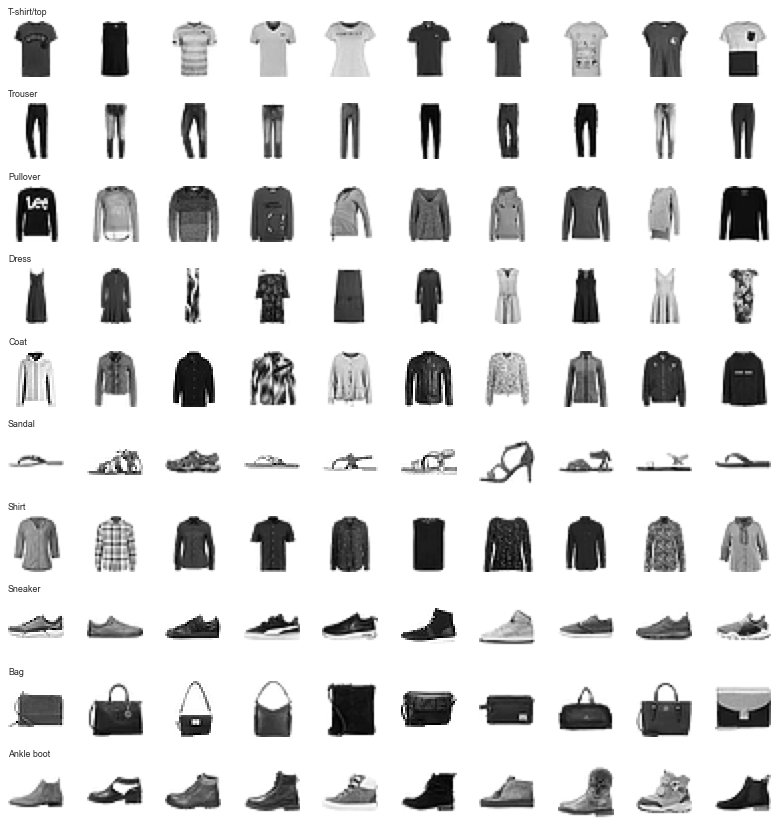

In [3]:
fig, axes = plt.subplots(10, 10, figsize=(10, 10.5))
for c in range(10):
    for i, idx in enumerate(np.where(labels == c)[0][:10]):
        axes[c, i].imshow(images[idx], cmap="gray_r")
        axes[c, i].axis("off")
    axes[c, 0].set_title(CLASSES[c], fontsize=8, loc="left")
plt.tight_layout()
plt.show()

**What we see.** Ten examples of each class, one class per row. Already some groups are visibly easy and some hard:
- **Trousers**, **bags** and the three kinds of **shoes** have distinctive shapes.
- **T-shirts, pullovers, coats and shirts** are all "a top with or without sleeves" at this tiny resolution. Even a person has to look twice at some of them.

Looking at real examples first is the image version of `df.head()`, and it already predicts where a model will struggle.

In [4]:
print(pd.Series(np.bincount(labels), index=CLASSES).to_frame("images").T)

        T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  \
images         1000     1000      1000   1000  1000    1000   1000     1000   

         Bag  Ankle boot  
images  1000        1000  


**What we see.** Exactly **1,000** images per class. The dataset was built to be **perfectly balanced**, so here, unlike in Notebooks 04 to 06, plain accuracy is a fair measure, and the "always guess one class" baseline is **10%**.

## 3. Pixels as data

In [5]:
X = images.reshape(len(images), -1) / 255.0
print("Share of pixels that are exactly 0 (pure background):", round((X == 0).mean(), 3))
ink = pd.Series((X > 0).mean(axis=1)).groupby(labels).mean()
ink.index = CLASSES
ink.sort_values().round(3).to_frame("share of pixels with ink").T

Share of pixels that are exactly 0 (pure background): 0.5


,Sandal,Sneaker,Trouser,Dress,Ankle boot,Bag,T-shirt/top,Coat,Shirt,Pullover
share of pixels with ink,0.322,0.338,0.353,0.433,0.484,0.589,0.595,0.609,0.627,0.652


**What we see.** Half of all pixels (**50%**) are pure background. The share of pixels with any "ink" already separates classes: **sandals** (about **32%**), **sneakers** and **trousers** (about 34 to 35%) are thin objects, while **pullovers** (about **65%**), shirts and coats fill most of the frame. One number per image, the amount of ink, is a first feature.

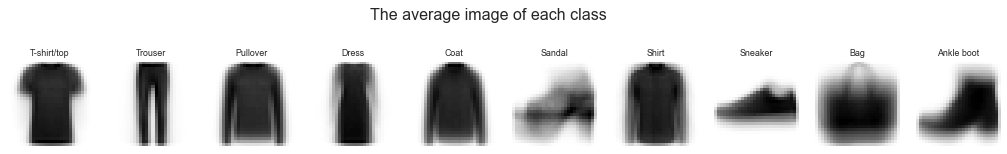

In [6]:
fig, axes = plt.subplots(1, 10, figsize=(16, 2.2))
for c, ax in enumerate(axes):
    ax.imshow(X[labels == c].mean(axis=0).reshape(28, 28), cmap="gray_r")
    ax.set_title(CLASSES[c], fontsize=8)
    ax.axis("off")
plt.suptitle("The average image of each class", y=1.05)
plt.show()

**What we see.** Averaging all 1,000 images of a class gives a blurred "typical" item. Trousers show two legs, sandals a light open shape, ankle boots a high heel. But the averages of **T-shirt, pullover, coat and shirt** are almost the same silhouette; they differ mainly in the sleeves (T-shirts have short ones) and in faint details inside the garment. What separates these four classes is small and local, which is exactly what simple methods struggle with.

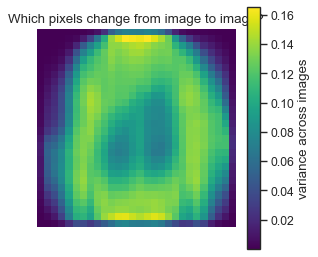

In [7]:
variance = X.var(axis=0).reshape(28, 28)
plt.figure(figsize=(4, 4))
plt.imshow(variance, cmap="viridis")
plt.colorbar(label="variance across images")
plt.title("Which pixels change from image to image?")
plt.axis("off")
plt.show()

**What we see.** A pixel that is the same in every image carries no information. The variance map shows that the **corners and the very edges** barely change, while the centre and the outline of the garments change a lot. Of the 784 pixels, many contribute very little, which suggests that the images could be described with far fewer numbers.

## 4. Compressing 784 pixels with PCA

### Intuition first
**Principal component analysis (PCA)** looks for the directions in which the images differ most. The first direction might be "how much ink", the second "wide top against tall shoe", and so on. Each image can then be described by how far it lies along each direction, a handful of numbers instead of 784.

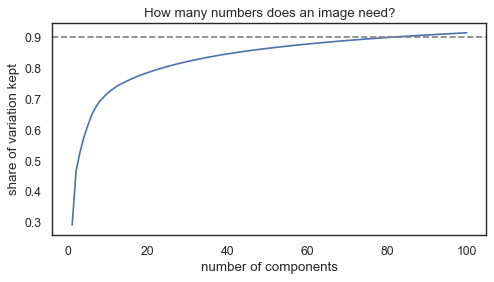

2 components keep 0.468  10 keep 0.719  90% needs 83 components


In [8]:
from sklearn.decomposition import PCA

pca = PCA().fit(X)
cumulative = np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(7, 3.5))
plt.plot(range(1, 101), cumulative[:100])
plt.axhline(0.9, color="grey", linestyle="--")
plt.xlabel("number of components")
plt.ylabel("share of variation kept")
plt.title("How many numbers does an image need?")
plt.show()
print("2 components keep", round(cumulative[1], 3), " 10 keep", round(cumulative[9], 3),
      " 90% needs", int(np.argmax(cumulative >= 0.9) + 1), "components")

**What we see.** Just **2** components keep **47%** of all the variation between images, **10** keep **72%**, and **83** components keep 90%. So the 784 pixels are highly redundant: about a tenth of the numbers keeps nine tenths of the information.

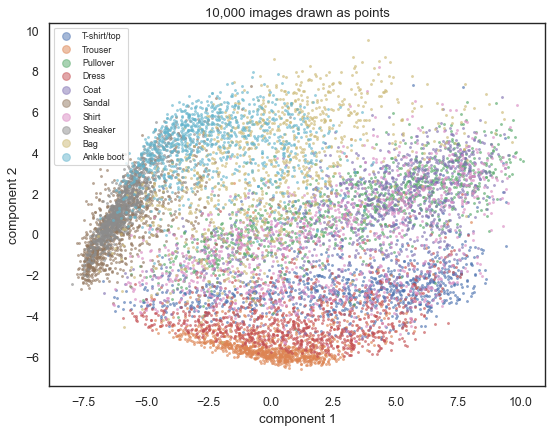

In [9]:
coords = PCA(n_components=2).fit_transform(X)
plt.figure(figsize=(8, 6))
for c in range(10):
    plt.scatter(coords[labels == c, 0], coords[labels == c, 1], s=3, alpha=0.5, label=CLASSES[c])
plt.legend(markerscale=4, fontsize=8, loc="best")
plt.xlabel("component 1")
plt.ylabel("component 2")
plt.title("10,000 images drawn as points")
plt.show()

**What we see.** Every image is now a point, and similar images land close together. Even with only two numbers per image, the **footwear** (sandals, sneakers, ankle boots) forms its own region, **trousers** form a separate group, and the **tops** (T-shirt, pullover, coat, shirt) pile up on top of each other. The picture predicts the difficulties before we train anything, just like the pair plot did for the penguins.

## 5. Simple classifiers on raw pixels

We hold out 30% of the images for testing and compare three simple methods:
- **Nearest centroid:** assign each image to the class whose **average image** (Section 3) it is closest to.
- **k nearest neighbours:** find the 5 most similar images in the training set and take a vote.
- **Logistic regression:** learn one weight per pixel per class.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestCentroid, KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(X, labels, test_size=0.3, random_state=42, stratify=labels)
models = {"Nearest centroid (average images)": NearestCentroid(),
          "5 nearest neighbours": KNeighborsClassifier(n_neighbors=5),
          "Logistic regression": LogisticRegression(max_iter=300)}
scores = {}
for name, model in models.items():
    scores[name] = accuracy_score(y_test, model.fit(X_train, y_train).predict(X_test))
pd.Series(scores, name="accuracy").to_frame()

,accuracy
Nearest centroid (average images),0.668
5 nearest neighbours,0.801
Logistic regression,0.811


**What we see.** Against a baseline of 10%:
- Comparing each image with the ten **average images** already gets **67%** right.
- **Nearest neighbours** reach **80%**, and **logistic regression** **81%**.

No method here knows that pixels next to each other belong together; each pixel is just an independent column. Even so, four out of five garments are recognised from raw pixels.

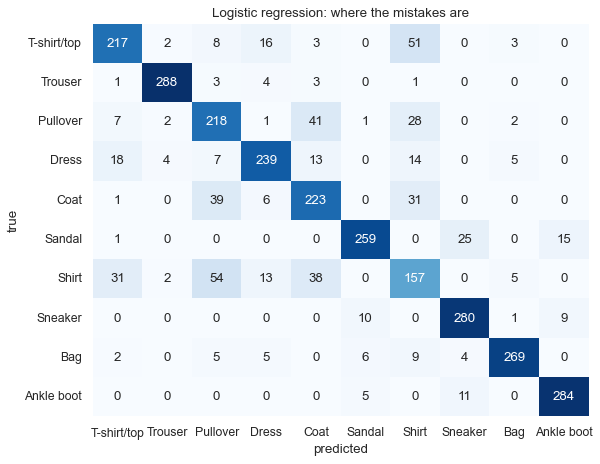

,Shirt,T-shirt/top,Pullover,Coat,Dress,Sandal,Bag,Sneaker,Ankle boot,Trouser
accuracy per class,0.523,0.723,0.727,0.743,0.797,0.863,0.897,0.933,0.947,0.96


In [11]:
pred = models["Logistic regression"].predict(X_test)
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, cbar=False)
plt.xlabel("predicted")
plt.ylabel("true")
plt.title("Logistic regression: where the mistakes are")
plt.show()
pd.Series(cm.diagonal() / cm.sum(axis=1), index=CLASSES).sort_values().round(3).to_frame("accuracy per class").T

**What we see.** The mistakes are not spread evenly; they sit in one corner of the table:
- **Shirt** is the hardest class by far: only **52%** of shirts are recognised. They are called T-shirt, pullover or coat.
- **Pullover** and **coat** are confused with each other (about 40 mistakes each way) and with shirt.
- **Trousers** (**96%**), **ankle boots** (**95%**) and **sneakers** (**93%**) are almost always right. Among the shoes, the few mistakes are between sandals, sneakers and boots, never with clothes.

Every one of these patterns was visible in Section 2 by eye, in the average images and in the PCA map. The exploration predicted the confusion matrix. To do better on the tops, a model must use **shapes and local details** such as collars, buttons and sleeves; that is exactly what convolutional neural networks are built for, and they reach about 90% or more on this data (see the deep learning notebooks of *From Python to Deep Learning and Fine-Tuning*).

## 6. Answer to the question

*How different do the ten classes look, and how far do simple methods get?*

1. An image is a **table of 784 numbers**; half of them are pure background, and about 80 directions found by PCA keep 90% of the information.
2. **Footwear, trousers and bags** look very different from everything else and are recognised 90 to 96% of the time.
3. **Tops** (T-shirt, pullover, coat, shirt) share the same silhouette; **shirts** are recognised only about half the time.
4. Simple methods on raw pixels reach about **80%**, eight times the 10% baseline. Closing the remaining gap needs models that understand **shape**, which is the starting point of deep learning.

## 🚀 Going further (for experienced students)

### A. What did logistic regression learn? Weights as pictures
Logistic regression has one weight per pixel for each class. Reshaped to 28 × 28, the weights become a picture of what the model looks for: red pixels push towards the class, blue pixels push away.

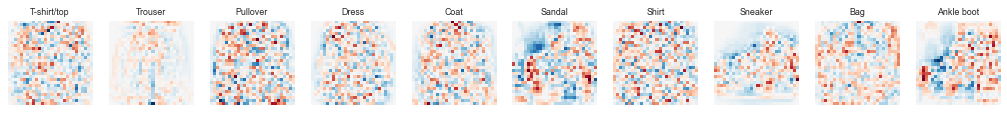

In [12]:
weights = models["Logistic regression"].coef_
fig, axes = plt.subplots(1, 10, figsize=(16, 2.2))
for c, ax in enumerate(axes):
    limit = np.abs(weights[c]).max()
    ax.imshow(weights[c].reshape(28, 28), cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_title(CLASSES[c], fontsize=8)
    ax.axis("off")
plt.show()

**What we see.** Some classes show a recognisable picture: the **sandal**, **sneaker** and **ankle boot** weights trace the outline of a shoe, and the **trouser** weights mark the gap between the legs. The tops look like noise: the model has no simple shape to rely on, and spreads its weights over many individual pixels, partly memorising the training images. Stronger regularisation smooths these pictures; a convolutional network replaces them with learned local patterns such as edges and collars.

### B. A better map than PCA: t-SNE
PCA keeps the **global** directions of variation. **t-SNE** tries instead to keep **neighbours** next to each other, which often separates groups much more clearly. It is slower, so we use 2,000 images.

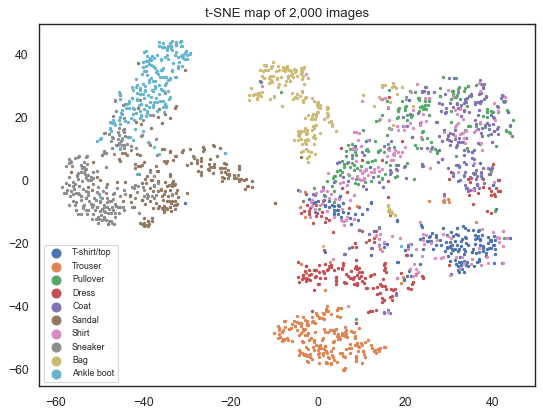

In [13]:
from sklearn.manifold import TSNE

sample = np.random.default_rng(42).choice(len(X), 2000, replace=False)
embedded = TSNE(n_components=2, init="pca", random_state=42).fit_transform(X[sample])
plt.figure(figsize=(8, 6))
for c in range(10):
    k = labels[sample] == c
    plt.scatter(embedded[k, 0], embedded[k, 1], s=4, label=CLASSES[c])
plt.legend(markerscale=4, fontsize=8)
plt.title("t-SNE map of 2,000 images")
plt.show()

**What we see.** t-SNE separates the classes far more clearly than the PCA map: **trousers**, **bags** and the three kinds of **footwear** form their own islands (and sneakers sit next to sandals), while **T-shirts**, **pullovers**, **coats** and **shirts** still overlap in one large region. Even a method designed to pull groups apart cannot separate the tops on raw pixels. Two cautions: distances **between** islands on a t-SNE map mean little, and the picture changes with its settings, so it is a tool for looking, not for measuring.

## ⚠️ Common pitfalls

- **Skipping the look.** Plot examples before modelling; images make problems visible that tables hide.
- **Forgetting to scale pixels.** Dividing by 255 keeps values between 0 and 1, which many methods need.
- **Reading accuracy without the confusion matrix.** An 81% model can be 95% right on some classes and 52% on another.
- **Assuming every pixel matters.** Many pixels never change; PCA shows how few numbers carry the information.
- **Expecting raw-pixel methods to understand shape.** They treat each pixel as a separate column; moving a garment by one pixel changes every column.

## ✏️ Exercises

### Exercise 1 (The most "average" shirt)
For the class **Shirt**, find the image closest to the class's average image, and the one furthest from it. Show both. What makes the far one unusual?

In [14]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
shirts = X[labels == 6]
distance = np.linalg.norm(shirts - shirts.mean(axis=0), axis=1)
fig, axes = plt.subplots(1, 2, figsize=(5, 2.8))
for ax, idx, title in zip(axes, [distance.argmin(), distance.argmax()], ["closest to average", "furthest"]):
    ax.imshow(shirts[idx].reshape(28, 28), cmap="gray_r")
    ax.set_title(title)
    ax.axis("off")
plt.show()
```

*The typical shirt is a plain grey top with long sleeves. The furthest one usually has strong patterns, unusual colours or an odd shape: exactly the kind of example that a method based on average images gets wrong.*
</details>

### Exercise 2 (Fewer numbers, same accuracy?)
Compress the images with PCA to **50** components (fitted on the training images only), and train the same logistic regression on the compressed data. How much accuracy is lost?

In [15]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
pca50 = PCA(n_components=50).fit(X_train)
small = LogisticRegression(max_iter=300).fit(pca50.transform(X_train), y_train)
print("accuracy with 50 numbers per image:", round(accuracy_score(y_test, small.predict(pca50.transform(X_test))), 3))
```

*With 50 numbers instead of 784, accuracy stays within about a point of the full model, and training is much faster. Fitting PCA on the training images only keeps the test set unseen.*
</details>

### Exercise 3 (Clothes or shoes?)
Make a two-class version of the problem: **footwear** (sandal, sneaker, ankle boot) against **everything else**. What accuracy does nearest centroid reach on this easier question?

In [16]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
is_shoe_train = np.isin(y_train, [5, 7, 9])
is_shoe_test = np.isin(y_test, [5, 7, 9])
nc = NearestCentroid().fit(X_train, is_shoe_train)
print("shoe or not, nearest centroid:", round(accuracy_score(is_shoe_test, nc.predict(X_test)), 3))
```

*Telling shoes from everything else is almost trivial, even for the simplest method, because shoes occupy a different region of the picture. How hard a problem is depends as much on the question as on the data.*
</details>

## 🔑 Key takeaways

- An image is a **table of numbers**; unrolled, an image dataset is an ordinary table with one column per pixel.
- **Look at examples and averages** first; they reveal which classes will be confused.
- Many pixels carry little information; **PCA** compresses 784 pixels into a few dozen numbers with little loss.
- Simple methods on raw pixels reach about **80%** here; the **confusion matrix** shows that almost all errors are among similar-looking tops.
- What remains needs models that understand **shape**: the motivation for convolutional neural networks.

---
**This is the last notebook of the first series.** The same route, *question, first look, one variable, pairs and groups, features, honest baselines, answer*, works on any dataset you meet next.

---
*© Ioannis Tsioulis. *From Questions to Answers: Classic Datasets, Fully Explored*. Prepared for educational use.*